# Brain MRI Tumor Classification with Transfer Learning

**Train, validate, evaluate, and interpret a MobileNetV2 image classifier (TensorFlow / Keras, Google Colab)**

> **Educational use only.** This project is not a medical device and must not be used to diagnose, screen, or guide treatment. Metrics and Grad-CAM maps do not establish clinical reliability or causal explanations. See [15. Limitations and responsible use](#scrollTo=sec-15-limits).

## Table of contents

*In Colab each link jumps to its section; the left sidebar (the ☰ icon) also shows this outline automatically.*

1. [Background and scope](#scrollTo=sec-1-background)
2. [Environment setup](#scrollTo=sec-2-setup)
3. [Configuration](#scrollTo=sec-3-config)
   * [3.1 Settings](#scrollTo=sec-3-config)
   * [3.2 Helper functions](#scrollTo=sec-3-2-helpers)
4. [Data preparation](#scrollTo=sec-4-data)
   * [4.1 Discover and validate the dataset](#scrollTo=sec-4-data)
   * [4.2 Check for duplicate images](#scrollTo=sec-4-2-duplicates)
   * [4.3 Build train / validation / test splits](#scrollTo=sec-4-3-splits)
   * [4.4 Inspect sample images](#scrollTo=sec-4-4-samples)
5. [Input pipeline](#scrollTo=sec-5-pipeline)
6. [Model](#scrollTo=sec-6-model)
7. [Training](#scrollTo=sec-7-training)
   * [7.1 Stage 1: train the classifier head](#scrollTo=sec-7-training)
   * [7.2 Stage 2: fine-tune the top backbone layers](#scrollTo=sec-7-2-finetune)
   * [7.3 Reload the best checkpoint and save run metadata](#scrollTo=sec-7-3-save)
8. [Evaluation and metrics](#scrollTo=sec-8-eval)
9. [Training curves and confusion matrix](#scrollTo=sec-9-curves)
10. [ROC and precision-recall curves](#scrollTo=sec-10-roc)
11. [Calibration and error review](#scrollTo=sec-11-calibration)
12. [Grad-CAM](#scrollTo=sec-12-gradcam)
13. [Predict a single image](#scrollTo=sec-13-inference)
14. [Save and download results](#scrollTo=sec-14-save)
15. [Limitations and responsible use](#scrollTo=sec-15-limits)
16. [References](#scrollTo=sec-16-refs)

---
## 1. Background and scope

**Task.** Classify 2-D brain MRI slices into tumor categories (for the dataset suggested below: `glioma`, `meningioma`, `pituitary`, and `notumor`). The notebook works with any image dataset arranged as one folder per class.

**Approach.** Transfer learning with **MobileNetV2** pre-trained on ImageNet [1, 2], trained in two stages [16]:

1. the pre-trained backbone is frozen and only a small classification head is trained;
2. the top backbone layers are unfrozen and fine-tuned with a much smaller learning rate.

Class-weighted cross-entropy compensates for class imbalance, mild geometric augmentation reduces overfitting, dropout [8] regularizes the head, Adam [7] is the optimizer, and early stopping and checkpointing monitor **validation loss**.

**Evaluation.** The held-out test split is evaluated only after the checkpoint is chosen. Besides accuracy the notebook reports per-class precision / sensitivity / specificity / F1, ROC-AUC and average precision, Matthews correlation [13], Cohen's kappa [14], log loss, the Brier score [12], expected calibration error [4], and bootstrap 95 % confidence intervals [15]. **Grad-CAM** [3] provides an optional coarse visual explanation.

**Pipeline at a glance**

```
Drive images → integrity + duplicate checks → stratified train/validation split
   → tf.data (decode, resize, cache) → augmentation + MobileNetV2 (frozen) → head training
   → fine-tune top layers → reload best checkpoint → evaluate on held-out test
   → ROC/PR, calibration, error review, Grad-CAM → artifacts saved to Drive
```

**Suggested dataset.** The *Brain Tumor MRI Dataset* on Kaggle [5] (CC0 licence; 7,023 images, about 5,712 for training and 1,311 for testing). It combines several public sources, including the figshare brain tumor dataset [6], so exact duplicates across the official Training and Testing folders are possible. Section 4.2 checks for them.

### How to run

1. In Google Drive create `MyDrive/brain_mri_project/` and put the dataset folders inside it:

   ```
   brain_mri_project/
   ├── Training/            (or train/)
   │   ├── glioma/
   │   ├── meningioma/
   │   ├── notumor/
   │   └── pituitary/
   └── Testing/             (or test/)  ← same class folders
   ```

   An optional `validation/` folder (next to `train/` and `test/`) is used as-is. Otherwise a stratified validation split is carved out of the training folder.
2. Upload this notebook to Drive and open it with Google Colab (or use **File → Upload notebook** inside Colab).
3. Choose **Runtime → Change runtime type → GPU** if available, review [3. Configuration](#scrollTo=sec-3-config), then **Runtime → Run all**. Keep the runtime connected until the last cell finishes.
4. Results are written to `artifacts/<run id>/` (and a `.zip` of it) in your Drive project folder.

### Output files

| File | Contents |
| --- | --- |
| `brain_mri_classifier.keras` | best model checkpoint (lowest validation loss) |
| `class_names.json`, `run_config.json` | class order, all settings, split sizes, library versions |
| `training_history.csv` | per-epoch loss and accuracy for both training stages |
| `metrics.json`, `validation_metrics.json` | all metrics for the test and validation splits |
| `test_predictions.csv`, `validation_predictions.csv` | per-image predictions with class probabilities |
| `test_probabilities.npz`, `validation_probabilities.npz` | raw probabilities for re-analysis |
| `*.png` | training curves, confusion matrices, ROC / PR, calibration, error examples, Grad-CAM |

**Privacy.** Upload only data you are authorized to share with Google. Do not upload identifiable or sensitive MRI data without appropriate authorization.

**Split caution.** Keep all scans from one patient in exactly one split. The automatic validation split below divides *images*, not patients, so if patient identifiers exist, prepare patient-level splits first. Leakage between splits is a common cause of over-optimistic results [18]. Keep the test set untouched while choosing a model.

---
## 2. Environment setup

The next two cells (a) install only the packages that are missing from the Colab runtime, then (b) import everything used in the notebook, mount Google Drive, and print library versions and the available GPU. No virtual environment is created and the dataset is not downloaded; Colab only needs access to your Drive files.

If no GPU is listed, training still works but is much slower: use **Runtime → Change runtime type**.

In [1]:
import importlib.util
import subprocess
import sys

REQUIRED_PACKAGES = {
    "tensorflow": "tensorflow>=2.16,<3",
    "cv2": "opencv-python-headless>=4.9",
    "sklearn": "scikit-learn>=1.4",
    "matplotlib": "matplotlib>=3.8",
    "pandas": "pandas>=2",
    "PIL": "pillow",
}
missing_packages = [
    package
    for module, package in REQUIRED_PACKAGES.items()
    if importlib.util.find_spec(module) is None
]
if missing_packages:
    print("Installing missing packages:", missing_packages)
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", *missing_packages]
    )
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
import hashlib
import json
import platform
import shutil
import warnings
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from IPython.display import display
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
    top_k_accuracy_score,
)
from sklearn.model_selection import train_test_split

try:
    from google.colab import drive

    IN_COLAB = True
    drive.mount("/content/drive")
except ImportError:
    IN_COLAB = False

plt.rcParams["figure.dpi"] = 110

print(f"Python {platform.python_version()} | TensorFlow {tf.__version__} | "
      f"scikit-learn {sklearn.__version__} | pandas {pd.__version__}")
gpus = tf.config.list_physical_devices("GPU")
print(f"Running in Colab: {IN_COLAB} | GPU(s): {gpus or 'None (training will be slow)'}")

Mounted at /content/drive
Python 3.13.16 | TensorFlow 2.21.0 | scikit-learn 1.6.1 | pandas 2.2.3
Running in Colab: True | GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
## 3. Configuration

### 3.1 Settings

Edit the values below before running; everything else adapts automatically.

| Setting | Meaning |
| --- | --- |
| `PROJECT_DIR` | Drive folder that contains the dataset folders |
| `IMAGE_SIZE`, `BATCH_SIZE` | input resolution (square) and batch size; try `BATCH_SIZE = 16` if GPU memory is limited |
| `VALIDATION_SPLIT` | share of the training folder used for validation (ignored if a `validation/` folder exists) |
| `CACHE_IN_MEMORY` | keep decoded images in RAM after the first epoch (much faster than re-reading Drive; needs roughly 150 KB per image) |
| `CHECK_DUPLICATES`, `DROP_DUPLICATES` | hash all files to find identical images; optionally drop them from the evaluation splits |
| `EPOCHS`, `FINE_TUNE_EPOCHS`, `FINE_TUNE_LAYERS` | length of stage 1, length of stage 2, and number of top backbone layers unfrozen in stage 2 (`0` skips stage 2) |
| `WEIGHTS` | `"imagenet"` downloads the pre-trained MobileNetV2 weights on first use; `None` trains from scratch and skips the download |
| `SEED` | random seed for splits, shuffling, and augmentation |

In [3]:
# ----------------------------- Paths -----------------------------
PROJECT_DIR = (
    Path("/content/drive/MyDrive/brain_mri_project")
    if IN_COLAB
    else Path("brain_mri_project")
)

# ----------------------------- Data ------------------------------
IMAGE_SIZE = 224
BATCH_SIZE = 32
VALIDATION_SPLIT = 0.20      # used only when there is no validation/ folder
CACHE_IN_MEMORY = True       # cache decoded uint8 images in RAM after epoch 1
CHECK_DUPLICATES = True      # hash files to find exact duplicates
DROP_DUPLICATES = True       # remove them so evaluation data is unseen
SHOW_SAMPLE_IMAGES = True

# --------------------------- Training ----------------------------
EPOCHS = 20                  # stage 1: classifier head
FINE_TUNE_EPOCHS = 5         # stage 2: set 0 to skip
FINE_TUNE_LAYERS = 30        # top backbone layers unfrozen in stage 2
LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-5
DROPOUT_RATE = 0.3
EARLY_STOPPING_PATIENCE = 5
WEIGHTS = "imagenet"         # or None to train from scratch
SEED = 42

# -------------------------- Evaluation ---------------------------
N_BOOTSTRAP = 1000
CALIBRATION_BINS = 15

# ----------------------- Derived / validation --------------------
if not 0.0 < VALIDATION_SPLIT < 1.0:
    raise ValueError("VALIDATION_SPLIT must be between 0 and 1.")
if IMAGE_SIZE < 32:
    raise ValueError("IMAGE_SIZE must be at least 32 for MobileNetV2.")

tf.keras.utils.set_random_seed(SEED)
RUN_ID = datetime.now().strftime("run_%Y%m%d_%H%M%S")
WORK_DIR = Path("/content") if IN_COLAB else Path("runs")
OUTPUT_DIR = WORK_DIR / f"brain_mri_{RUN_ID}"          # fast local scratch
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
MODEL_PATH = OUTPUT_DIR / "brain_mri_classifier.keras"
SAVE_DIR = PROJECT_DIR / "artifacts" / RUN_ID          # persistent copy
print(f"Run id: {RUN_ID}\nScratch folder: {OUTPUT_DIR}\nResults will be saved to: {SAVE_DIR}")

Run id: run_20261117_152417
Scratch folder: /content/brain_mri_run_20261117_152417
Results will be saved to: /content/drive/MyDrive/brain_mri_project/artifacts/run_20261117_152417


### 3.2 Helper functions

Small utilities used throughout: JSON writing that tolerates NumPy types, figure saving, and `sync_results()`, which copies the run folder to Drive and refreshes the `.zip` archive. It is called after evaluation (so results survive a disconnect) and again at the end.

In [4]:
def to_builtin(obj):
    """JSON fallback that converts NumPy scalars and arrays."""
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    raise TypeError(f"Cannot serialize {type(obj).__name__}")


def write_json(path, payload):
    with Path(path).open("w", encoding="utf-8") as file:
        json.dump(payload, file, indent=2, allow_nan=False, default=to_builtin)


def save_figure(fig, filename):
    fig.savefig(OUTPUT_DIR / filename, dpi=150, bbox_inches="tight")


def sync_results():
    """Copy the run folder to the project folder and refresh the .zip archive."""
    SAVE_DIR.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(OUTPUT_DIR, SAVE_DIR, dirs_exist_ok=True)
    archive = shutil.make_archive(str(SAVE_DIR), "zip", root_dir=SAVE_DIR)
    print(f"Results saved to: {SAVE_DIR}\nDownloadable archive: {archive}")
    return archive

---
## 4. Data preparation

### 4.1 Discover and validate the dataset

This cell finds the split folders, reads the class names from the training folder, verifies that every split has the same classes and that no class is empty, and lists the image files. Hidden folders such as `.ipynb_checkpoints` and macOS `._*` files are ignored.

In [5]:
SUPPORTED_EXTENSIONS = {".bmp", ".gif", ".jpeg", ".jpg", ".png"}

if not PROJECT_DIR.is_dir():
    raise FileNotFoundError(
        f"Project folder not found: {PROJECT_DIR}. Update PROJECT_DIR in the configuration cell."
    )
DATA_DIR = PROJECT_DIR

if (DATA_DIR / "Training").is_dir() and (DATA_DIR / "Testing").is_dir():
    TRAIN_DIR, TEST_DIR = DATA_DIR / "Training", DATA_DIR / "Testing"
    VALIDATION_DIR = None
elif (DATA_DIR / "train").is_dir() and (DATA_DIR / "test").is_dir():
    TRAIN_DIR, TEST_DIR = DATA_DIR / "train", DATA_DIR / "test"
    VALIDATION_DIR = DATA_DIR / "validation"
    if not VALIDATION_DIR.is_dir():
        VALIDATION_DIR = None
else:
    raise FileNotFoundError(
        f"Expected Training/ and Testing/, or train/ and test/, under {DATA_DIR}."
    )


def is_visible(path, root):
    """False for hidden / system entries such as .ipynb_checkpoints or __MACOSX."""
    return not any(part.startswith((".", "__")) for part in path.relative_to(root).parts)


def class_folders(split_dir):
    return sorted(
        p.name for p in split_dir.iterdir() if p.is_dir() and is_visible(p, split_dir)
    )


def collect_images(split_dir, class_names):
    paths, labels = [], []
    for label, class_name in enumerate(class_names):
        class_dir = split_dir / class_name
        files = sorted(
            str(p)
            for p in class_dir.rglob("*")
            if p.is_file()
            and p.suffix.lower() in SUPPORTED_EXTENSIONS
            and is_visible(p, class_dir)
        )
        paths.extend(files)
        labels.extend([label] * len(files))
    return paths, labels


SPLIT_DIRS = {"train": TRAIN_DIR, "test": TEST_DIR}
if VALIDATION_DIR is not None:
    SPLIT_DIRS["validation"] = VALIDATION_DIR

class_names = class_folders(TRAIN_DIR)
if len(class_names) < 2:
    raise ValueError(f"Need at least two class folders in {TRAIN_DIR}; found {class_names}.")
for split_name, split_dir in SPLIT_DIRS.items():
    if class_folders(split_dir) != class_names:
        raise ValueError(
            f"Classes in {split_name} {class_folders(split_dir)} differ from training classes {class_names}."
        )
N_CLASSES = len(class_names)

raw_splits = {name: collect_images(d, class_names) for name, d in SPLIT_DIRS.items()}
raw_counts = pd.DataFrame(
    {
        name: pd.Series(Counter(class_names[label] for label in labels))
        for name, (_, labels) in raw_splits.items()
    }
).reindex(class_names).fillna(0).astype(int)
if (raw_counts == 0).any().any():
    raise ValueError(f"Every class needs images in every split:\n{raw_counts}")

print(f"Dataset folder: {DATA_DIR}")
print("Layout:", "train / validation / test" if VALIDATION_DIR else "train / test (validation will be split from train)")
print("Class order:", class_names)
display(raw_counts)

Dataset folder: /content/drive/MyDrive/brain_mri_project
Layout: train / test (validation will be split from train)
Class order: ['glioma', 'meningioma', 'notumor', 'pituitary']


,train,test
glioma,1400,400
meningioma,1400,400
notumor,1400,400
pituitary,1400,400


### 4.2 Check for duplicate images

Exact duplicates between training and evaluation data inflate metrics. Every file is hashed (SHA-256) to find byte-identical images inside each split, across splits, and with conflicting labels. This detects **exact** copies only; re-encoded or slightly cropped near-duplicates and slices from the same patient are not detected. Set `CHECK_DUPLICATES = False` to skip it.

In [6]:
def file_digest(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


digests = {}
if CHECK_DUPLICATES:
    all_paths = [p for paths, _ in raw_splits.values() for p in paths]
    with ThreadPoolExecutor(max_workers=16) as pool:
        digests = dict(zip(all_paths, pool.map(file_digest, all_paths)))

    split_hashes = {
        name: [digests[p] for p in paths] for name, (paths, _) in raw_splits.items()
    }
    rows = [
        {"check": f"repeated files inside {name}", "count": len(h) - len(set(h))}
        for name, h in split_hashes.items()
    ]
    names = list(split_hashes)
    for i, first in enumerate(names):
        for second in names[i + 1:]:
            rows.append(
                {
                    "check": f"identical images in both {first} and {second}",
                    "count": len(set(split_hashes[first]) & set(split_hashes[second])),
                }
            )
    labels_by_digest = {}
    for paths, labels in raw_splits.values():
        for path, label in zip(paths, labels):
            labels_by_digest.setdefault(digests[path], set()).add(label)
    rows.append(
        {
            "check": "identical images carrying different labels",
            "count": sum(len(v) > 1 for v in labels_by_digest.values()),
        }
    )
    duplicate_report = pd.DataFrame(rows).set_index("check")
    display(duplicate_report)
else:
    duplicate_report = None
    print("Duplicate check skipped (CHECK_DUPLICATES = False).")

,count
check,
repeated files inside train,171
repeated files inside test,16
identical images in both train and test,0
identical images carrying different labels,0


### 4.3 Build train / validation / test splits

If `DROP_DUPLICATES` is on, repeated images are removed from training, and images that also occur in training (or validation) are removed from the validation and test splits, so the evaluation data is never seen during training. When there is no `validation/` folder, a **stratified** validation split is taken from the de-duplicated training pool. Finally the cell computes class weights (inverse frequency) from the training split.

Removed because of exact duplicates: {'train: repeated images': 171, 'test: also in train/validation': 0}


,train,validation,test
glioma,1120,280,400
meningioma,1109,277,400
notumor,1025,256,400
pituitary,1089,273,400
TOTAL,4343,1086,1600


Class weights: {'glioma': 0.969, 'meningioma': 0.979, 'notumor': 1.059, 'pituitary': 0.997}


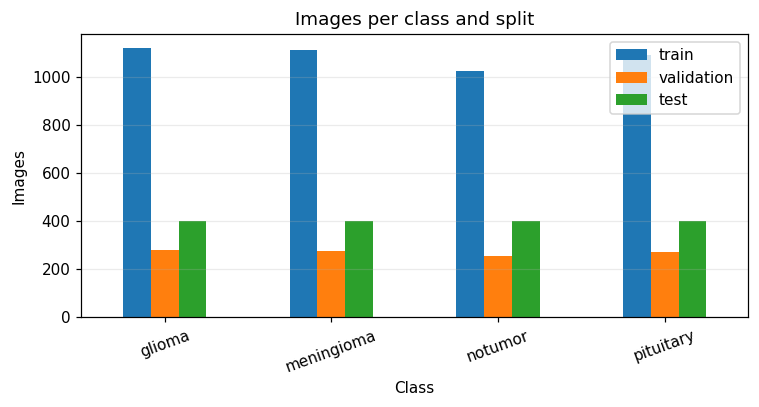

In [7]:
def drop_repeats(paths, labels, blocked=frozenset(), dedupe_within=False):
    """Keep images whose content hash is not blocked (and not repeated, if asked)."""
    kept_paths, kept_labels, seen = [], [], set()
    for path, label in zip(paths, labels):
        digest = digests[path]
        if digest in blocked or (dedupe_within and digest in seen):
            continue
        seen.add(digest)
        kept_paths.append(path)
        kept_labels.append(label)
    return kept_paths, kept_labels


filtering = CHECK_DUPLICATES and DROP_DUPLICATES
removed = {}

pool_paths, pool_labels = raw_splits["train"]
if filtering:
    before = len(pool_paths)
    pool_paths, pool_labels = drop_repeats(pool_paths, pool_labels, dedupe_within=True)
    removed["train: repeated images"] = before - len(pool_paths)

if VALIDATION_DIR is None:
    if min(Counter(pool_labels).values()) < 2:
        raise ValueError("Each class needs at least 2 training images to create a stratified split.")
    train_paths, validation_paths, train_labels, validation_labels = train_test_split(
        pool_paths,
        pool_labels,
        test_size=VALIDATION_SPLIT,
        stratify=pool_labels,
        random_state=SEED,
    )
else:
    train_paths, train_labels = pool_paths, pool_labels
    validation_paths, validation_labels = raw_splits["validation"]
    if filtering:
        before = len(validation_paths)
        validation_paths, validation_labels = drop_repeats(
            validation_paths, validation_labels, blocked={digests[p] for p in train_paths}
        )
        removed["validation: also in train"] = before - len(validation_paths)

test_paths, test_labels = raw_splits["test"]
if filtering:
    before = len(test_paths)
    test_paths, test_labels = drop_repeats(
        test_paths,
        test_labels,
        blocked={digests[p] for p in list(train_paths) + list(validation_paths)},
    )
    removed["test: also in train/validation"] = before - len(test_paths)

train_labels = np.asarray(train_labels, dtype=np.int32)
validation_labels = np.asarray(validation_labels, dtype=np.int32)
test_labels = np.asarray(test_labels, dtype=np.int32)


def count_by_class(labels):
    return pd.Series(Counter(class_names[int(i)] for i in labels)).reindex(class_names).fillna(0).astype(int)


split_counts = pd.DataFrame(
    {
        "train": count_by_class(train_labels),
        "validation": count_by_class(validation_labels),
        "test": count_by_class(test_labels),
    }
)
if (split_counts == 0).any().any():
    raise ValueError(f"A class became empty in some split after filtering:\n{split_counts}")

if removed:
    print("Removed because of exact duplicates:", removed)
display(pd.concat([split_counts, split_counts.sum().rename("TOTAL").to_frame().T]))

train_class_counts = np.bincount(train_labels, minlength=N_CLASSES)
class_weights = {
    class_id: float(len(train_labels) / (N_CLASSES * count))
    for class_id, count in enumerate(train_class_counts)
}
print("Class weights:", {class_names[i]: round(w, 3) for i, w in class_weights.items()})

fig, ax = plt.subplots(figsize=(7, 3.8))
split_counts.plot.bar(ax=ax, rot=20)
ax.set(title="Images per class and split", xlabel="Class", ylabel="Images")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
save_figure(fig, "class_distribution.png")
plt.show()

### 4.4 Inspect sample images

A quick visual sanity check: random training images for each class. Set `SHOW_SAMPLE_IMAGES = False` to skip this cell if you prefer not to display scans.

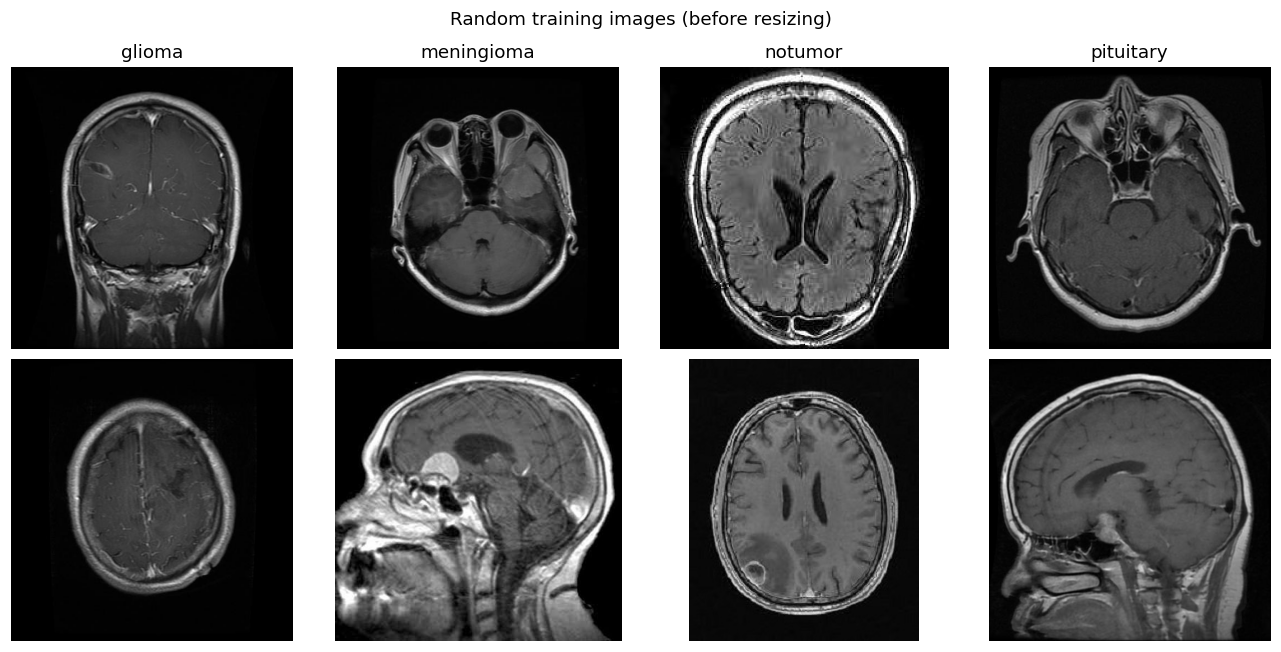

In [8]:
if SHOW_SAMPLE_IMAGES:
    rng = np.random.default_rng(SEED)
    per_class = 2
    fig, axes = plt.subplots(per_class, N_CLASSES, figsize=(3 * N_CLASSES, 3 * per_class), squeeze=False)
    for class_id, class_name in enumerate(class_names):
        candidates = [p for p, l in zip(train_paths, train_labels) if l == class_id]
        chosen = rng.choice(candidates, size=min(per_class, len(candidates)), replace=False)
        for row in range(per_class):
            axis = axes[row, class_id]
            axis.axis("off")
            if row < len(chosen):
                axis.imshow(Image.open(chosen[row]).convert("RGB"))
                if row == 0:
                    axis.set_title(class_name)
    plt.suptitle("Random training images (before resizing)")
    plt.tight_layout()
    plt.show()
else:
    print("Sample images skipped (SHOW_SAMPLE_IMAGES = False).")

---
## 5. Input pipeline

A `tf.data` pipeline reads each file, decodes it to 3-channel RGB, resizes it to `IMAGE_SIZE × IMAGE_SIZE`, stores it as compact `uint8` (optionally cached in RAM), and casts to `float32` per batch. Only the training dataset is shuffled. Validation and test datasets keep a fixed order, so predictions line up exactly with the file lists. Pixel scaling for MobileNetV2 happens *inside* the model, so the saved model accepts raw 0-255 images.

In [9]:
AUTOTUNE = tf.data.AUTOTUNE


def load_image(path, label):
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (IMAGE_SIZE, IMAGE_SIZE), method="bilinear")
    return tf.cast(tf.round(image), tf.uint8), label


def make_dataset(paths, labels, training):
    dataset = tf.data.Dataset.from_tensor_slices(
        (np.asarray(paths, dtype=str), np.asarray(labels, dtype=np.int32))
    )
    dataset = dataset.map(load_image, num_parallel_calls=AUTOTUNE)
    if CACHE_IN_MEMORY:
        dataset = dataset.cache()
    if training:
        dataset = dataset.shuffle(min(len(paths), 2048), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return dataset.prefetch(AUTOTUNE)


train_ds = make_dataset(train_paths, train_labels, training=True)
validation_ds = make_dataset(validation_paths, validation_labels, training=False)
test_ds = make_dataset(test_paths, test_labels, training=False)

# Sanity check on a single file (avoids partially filling the cache).
check_image, _ = load_image(tf.constant(train_paths[0]), tf.constant(0))
print(f"Example image tensor: shape={tuple(check_image.shape)}, dtype={check_image.dtype.name}, "
      f"range=[{int(tf.reduce_min(check_image))}, {int(tf.reduce_max(check_image))}]")
print(f"Batches per epoch: train={len(train_ds)}, validation={len(validation_ds)}, test={len(test_ds)}")

Example image tensor: shape=(224, 224, 3), dtype=uint8, range=[12, 255]
Batches per epoch: train=136, validation=34, test=50


---
## 6. Model

`augmentation (rotation, zoom, translation; training only) → rescale to [-1, 1] → MobileNetV2 backbone → global average pooling → dropout → dense logits → softmax`

Augmentation uses constant (black) fill and no flips. The backbone starts frozen. Its batch-normalization layers always run in inference mode, which keeps the pre-trained statistics stable during fine-tuning.

In [10]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomRotation(0.05, fill_mode="constant", seed=SEED),
        tf.keras.layers.RandomZoom(0.10, fill_mode="constant", seed=SEED),
        tf.keras.layers.RandomTranslation(0.05, 0.05, fill_mode="constant", seed=SEED),
    ],
    name="data_augmentation",
)

inputs = tf.keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3), name="image")
augmented = data_augmentation(inputs)
normalized = tf.keras.layers.Rescaling(
    scale=1.0 / 127.5, offset=-1, name="mobilenet_preprocess"
)(augmented)
backbone = tf.keras.applications.MobileNetV2(
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    include_top=False,
    weights=WEIGHTS,
    name="feature_extractor",
)
backbone.trainable = False
features = backbone(normalized, training=False)
pooled = tf.keras.layers.GlobalAveragePooling2D(name="global_pool")(features)
dropped = tf.keras.layers.Dropout(DROPOUT_RATE, name="dropout")(pooled)
logits = tf.keras.layers.Dense(N_CLASSES, name="class_logits")(dropped)
outputs = tf.keras.layers.Activation("softmax", name="predictions")(logits)
model = tf.keras.Model(inputs, outputs, name="brain_mri_classifier")
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "brain_mri_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocess            │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_extractor (Functional)  │ (None, 7, 7, 1280)     │     2,257,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_pool                     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_logits (Dense)            │ (None, 4)              │         5,124 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Activation)        │ (None, 4)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

---
## 7. Training

Training metrics are measured with augmentation and dropout switched on, while validation metrics are not, so a training curve that sits *below* the validation curve early on is normal.

### 7.1 Stage 1: train the classifier head

In [11]:
def make_callbacks(initial_best=None):
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=EARLY_STOPPING_PATIENCE, restore_best_weights=True
        ),
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(MODEL_PATH),
            monitor="val_loss",
            save_best_only=True,
            initial_value_threshold=initial_best,
        ),
    ]


def history_frame(history, phase):
    frame = pd.DataFrame(history.history)
    frame.insert(0, "epoch", range(1, len(frame) + 1))
    frame.insert(0, "phase", phase)
    return frame


history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=make_callbacks(),
)
history_frames = [history_frame(history, "frozen_backbone")]
best_validation_loss = float(min(history.history["val_loss"]))
print(f"Best validation loss after stage 1: {best_validation_loss:.4f}")

Epoch 1/20
136/136 ━━━━━━━━━━━━━━━━━━━━ 34s 141ms/step - accuracy: 0.7207 - loss: 0.7177 - val_accuracy: 0.8011 - val_loss: 0.5335
Epoch 2/20
136/136 ━━━━━━━━━━━━━━━━━━━━ 10s 70ms/step - accuracy: 0.8296 - loss: 0.4526 - val_accuracy: 0.7735 - val_loss: 0.5972
Epoch 3/20
136/136 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.8568 - loss: 0.3822 - val_accuracy: 0.7808 - val_loss: 0.5953
Epoch 4/20
136/136 ━━━━━━━━━━━━━━━━━━━━ 11s 79ms/step - accuracy: 0.8607 - loss: 0.3590 - val_accuracy: 0.8029 - val_loss: 0.5298
Epoch 5/20
136/136 ━━━━━━━━━━━━━━━━━━━━ 10s 71ms/step - accuracy: 0.8743 - loss: 0.3347 - val_accuracy: 0.7753 - val_loss: 0.6235
Epoch 6/20
136/136 ━━━━━━━━━━━━━━━━━━━━ 10s 75ms/step - accuracy: 0.8784 - loss: 0.3245 - val_accuracy: 0.7891 - val_loss: 0.5877
Epoch 7/20
136/136 ━━━━━━━━━━━━━━━━━━━━ 11s 79ms/step - accuracy: 0.8828 - loss: 0.3189 - val_accuracy: 0.8343 - val_loss: 0.4510
Epoch 8/20
136/136 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.8879 - loss: 0.3008 -

### 7.2 Stage 2: fine-tune the top backbone layers

The last `FINE_TUNE_LAYERS` layers of the backbone (excluding batch normalization) are unfrozen and trained with learning rate `FINE_TUNE_LEARNING_RATE`. The checkpoint file is only replaced if validation loss beats the best value from stage 1.

In [12]:
if FINE_TUNE_EPOCHS > 0 and FINE_TUNE_LAYERS > 0:
    backbone = model.get_layer("feature_extractor")
    backbone.trainable = True
    tail_ids = {
        id(layer)
        for layer in backbone.layers[-FINE_TUNE_LAYERS:]
        if not isinstance(layer, tf.keras.layers.BatchNormalization)
    }
    for layer in backbone.layers:
        layer.trainable = id(layer) in tail_ids
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=FINE_TUNE_LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    print(f"Unfrozen backbone layers: {len(tail_ids)} | "
          f"trainable weight tensors: {len(model.trainable_weights)}")
    fine_tune_history = model.fit(
        train_ds,
        validation_data=validation_ds,
        epochs=FINE_TUNE_EPOCHS,
        class_weight=class_weights,
        callbacks=make_callbacks(initial_best=best_validation_loss),
    )
    history_frames.append(history_frame(fine_tune_history, "fine_tuning"))
else:
    print("Fine-tuning skipped (FINE_TUNE_EPOCHS or FINE_TUNE_LAYERS is 0).")

Unfrozen backbone layers: 19 | trainable weight tensors: 12
Epoch 1/5
136/136 ━━━━━━━━━━━━━━━━━━━━ 20s 102ms/step - accuracy: 0.8936 - loss: 0.2736 - val_accuracy: 0.8858 - val_loss: 0.3210
Epoch 2/5
136/136 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.9153 - loss: 0.2322 - val_accuracy: 0.8591 - val_loss: 0.3873
Epoch 3/5
136/136 ━━━━━━━━━━━━━━━━━━━━ 12s 92ms/step - accuracy: 0.9208 - loss: 0.2165 - val_accuracy: 0.8904 - val_loss: 0.3047
Epoch 4/5
136/136 ━━━━━━━━━━━━━━━━━━━━ 12s 89ms/step - accuracy: 0.9261 - loss: 0.2013 - val_accuracy: 0.8656 - val_loss: 0.3825
Epoch 5/5
136/136 ━━━━━━━━━━━━━━━━━━━━ 11s 83ms/step - accuracy: 0.9335 - loss: 0.1750 - val_accuracy: 0.8821 - val_loss: 0.3316


### 7.3 Reload the best checkpoint and save run metadata

The best checkpoint (lowest validation loss across both stages) is reloaded from disk, so everything downstream evaluates exactly the file that gets saved. The cell also writes the training history, class order, and a complete run configuration for reproducibility.

In [13]:
model = tf.keras.models.load_model(MODEL_PATH)

history_df = pd.concat(history_frames, ignore_index=True)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)
best = history_df.loc[history_df["val_loss"].idxmin()]
print(f"Best checkpoint: phase={best['phase']}, epoch={int(best['epoch'])}, "
      f"val_loss={best['val_loss']:.4f}, val_accuracy={best['val_accuracy']:.4f}")

write_json(OUTPUT_DIR / "class_names.json", class_names)
write_json(
    OUTPUT_DIR / "run_config.json",
    {
        "run_id": RUN_ID,
        "image_size": IMAGE_SIZE,
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "fine_tune_epochs": FINE_TUNE_EPOCHS,
        "fine_tune_layers": FINE_TUNE_LAYERS,
        "learning_rate": LEARNING_RATE,
        "fine_tune_learning_rate": FINE_TUNE_LEARNING_RATE,
        "dropout_rate": DROPOUT_RATE,
        "early_stopping_patience": EARLY_STOPPING_PATIENCE,
        "weights": WEIGHTS,
        "seed": SEED,
        "validation_split": None if VALIDATION_DIR is not None else VALIDATION_SPLIT,
        "validation_source": "validation folder" if VALIDATION_DIR is not None else "stratified split of training folder",
        "duplicates_checked": CHECK_DUPLICATES,
        "duplicates_dropped": bool(CHECK_DUPLICATES and DROP_DUPLICATES),
        "images_removed_as_duplicates": removed,
        "class_names": class_names,
        "class_weights": {class_names[i]: w for i, w in class_weights.items()},
        "split_sizes": {
            "train": int(len(train_labels)),
            "validation": int(len(validation_labels)),
            "test": int(len(test_labels)),
        },
        "versions": {
            "python": platform.python_version(),
            "tensorflow": tf.__version__,
            "scikit_learn": sklearn.__version__,
            "numpy": np.__version__,
            "pandas": pd.__version__,
        },
    },
)

Best checkpoint: phase=fine_tuning, epoch=3, val_loss=0.3047, val_accuracy=0.8904


---
## 8. Evaluation and metrics

The validation split was used to choose the checkpoint, so its scores are **optimistic**; the held-out test split gives the honest estimate and should be evaluated once.

* **Accuracy / balanced accuracy**: overall hit rate / mean per-class recall (robust to imbalance).
* **Precision, sensitivity (recall), specificity, F1**: per class, one-vs-rest. Macro averages weight all classes equally.
* **ROC-AUC and average precision (AP)**: threshold-free ranking quality per class (one-vs-rest).
* **MCC** [13] and **Cohen's kappa** [14]: chance-corrected agreement summaries.
* **Log loss, Brier score** [12], **ECE** [4]: quality of the predicted probabilities (calibration).
* **Top-2 accuracy**: true class is among the two highest-scoring classes (only for more than two classes).
* **95 % bootstrap confidence intervals** [15]: the test set is resampled with replacement `N_BOOTSTRAP` times; the 2.5th and 97.5th percentiles show how much a score could move because of the finite test sample. They do not capture patient-level or dataset-shift uncertainty.

Undefined values (for example specificity when a class has no negatives) are stored as `null`.

In [14]:
def safe_divide(numerator, denominator):
    return float(numerator / denominator) if denominator else None


def mean_or_none(values):
    values = list(values)
    return float(np.mean(values)) if values and all(v is not None for v in values) else None


def calibration_summary(y_true, probabilities, n_bins=CALIBRATION_BINS):
    """Top-label reliability statistics (equal-width bins, last bin closed)."""
    confidence = probabilities.max(axis=1)
    correct = (probabilities.argmax(axis=1) == y_true).astype(float)
    bin_ids = np.minimum((confidence * n_bins).astype(int), n_bins - 1)
    counts = np.bincount(bin_ids, minlength=n_bins)
    populated = counts > 0
    mean_confidence = np.bincount(bin_ids, weights=confidence, minlength=n_bins)[populated] / counts[populated]
    accuracy = np.bincount(bin_ids, weights=correct, minlength=n_bins)[populated] / counts[populated]
    ece = float(np.sum(counts[populated] / counts.sum() * np.abs(accuracy - mean_confidence)))
    return ece, mean_confidence, accuracy, counts[populated]


def bootstrap_ci(y_true, y_pred, metric, n_resamples=N_BOOTSTRAP, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    values = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for _ in range(n_resamples):
            idx = rng.integers(0, n, n)
            values.append(metric(y_true[idx], y_pred[idx]))
    low, high = np.percentile(values, [2.5, 97.5])
    return float(low), float(high)


eval_cache = {}


def evaluate_split(split_name, dataset, image_paths, labels):
    class_ids = list(range(N_CLASSES))
    y_true = np.asarray(labels, dtype=np.int64)
    probabilities = model.predict(dataset, verbose=0).astype(np.float64)
    if probabilities.shape[0] != y_true.shape[0]:
        raise RuntimeError("Prediction count does not match label count.")
    probabilities /= probabilities.sum(axis=1, keepdims=True)
    y_pred = probabilities.argmax(axis=1)

    report = classification_report(
        y_true, y_pred, labels=class_ids, target_names=class_names,
        output_dict=True, zero_division=0,
    )
    matrix = confusion_matrix(y_true, y_pred, labels=class_ids)
    tp = np.diag(matrix)
    fp = matrix.sum(axis=0) - tp
    fn = matrix.sum(axis=1) - tp
    tn = matrix.sum() - (tp + fp + fn)
    specificity = {class_names[i]: safe_divide(tn[i], tn[i] + fp[i]) for i in class_ids}

    roc_auc, average_precision = {}, {}
    for i, name in enumerate(class_names):
        positive = y_true == i
        roc_auc[name] = (
            float(roc_auc_score(positive, probabilities[:, i]))
            if positive.any() and (~positive).any() else None
        )
        average_precision[name] = (
            float(average_precision_score(positive, probabilities[:, i]))
            if positive.any() else None
        )

    true_class_probability = probabilities[np.arange(len(y_true)), y_true]
    log_loss = float(-np.log(np.clip(true_class_probability, 1e-7, 1.0)).mean())
    kappa = cohen_kappa_score(y_true, y_pred)
    ece, _, _, _ = calibration_summary(y_true, probabilities)

    ci_metrics = {
        "accuracy": accuracy_score,
        "balanced_accuracy": balanced_accuracy_score,
        "macro_f1": lambda t, p: f1_score(t, p, labels=class_ids, average="macro", zero_division=0),
    }
    intervals = {}
    for metric_name, function in ci_metrics.items():
        low, high = bootstrap_ci(y_true, y_pred, function)
        intervals[metric_name] = {
            "estimate": float(function(y_true, y_pred)),
            "ci_low": low,
            "ci_high": high,
        }

    metrics = {
        f"{split_name}_samples": int(len(y_true)),
        f"{split_name}_loss": log_loss,
        "log_loss": log_loss,
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "top_2_accuracy": (
            float(top_k_accuracy_score(y_true, probabilities, k=2, labels=class_ids))
            if N_CLASSES > 2 else None
        ),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_precision": float(report["macro avg"]["precision"]),
        "weighted_precision": float(report["weighted avg"]["precision"]),
        "macro_f1": float(report["macro avg"]["f1-score"]),
        "weighted_f1": float(report["weighted avg"]["f1-score"]),
        "per_class_precision": {n: float(report[n]["precision"]) for n in class_names},
        "per_class_sensitivity": {n: float(report[n]["recall"]) for n in class_names},
        "per_class_f1": {n: float(report[n]["f1-score"]) for n in class_names},
        "per_class_specificity": specificity,
        "macro_specificity": mean_or_none(specificity.values()),
        "confusion_matrix": matrix.tolist(),
        "matthews_correlation_coefficient": float(matthews_corrcoef(y_true, y_pred)),
        "cohen_kappa": float(kappa) if np.isfinite(kappa) else None,
        "multiclass_brier_score": float(
            np.mean(np.sum((probabilities - np.eye(N_CLASSES)[y_true]) ** 2, axis=1))
        ),
        "expected_calibration_error": ece,
        "calibration_bins": CALIBRATION_BINS,
        "per_class_roc_auc_ovr": roc_auc,
        "per_class_average_precision_ovr": average_precision,
        "macro_roc_auc_ovr": mean_or_none(roc_auc.values()),
        "macro_average_precision_ovr": mean_or_none(average_precision.values()),
        "bootstrap_95ci": intervals,
        "bootstrap_resamples": N_BOOTSTRAP,
        "classification_report": report,
        "class_names": class_names,
    }

    write_json(
        OUTPUT_DIR / ("metrics.json" if split_name == "test" else f"{split_name}_metrics.json"),
        metrics,
    )
    predictions = pd.DataFrame(
        {
            "image_path": image_paths,
            "true_class": [class_names[i] for i in y_true],
            "predicted_class": [class_names[i] for i in y_pred],
            "confidence": probabilities.max(axis=1),
            "correct": y_pred == y_true,
        }
    )
    for i, name in enumerate(class_names):
        predictions[f"prob_{name}"] = probabilities[:, i]
    predictions.to_csv(OUTPUT_DIR / f"{split_name}_predictions.csv", index=False, float_format="%.6f")
    np.savez_compressed(
        OUTPUT_DIR / f"{split_name}_probabilities.npz",
        y_true=y_true, probabilities=probabilities, class_names=np.asarray(class_names),
    )
    eval_cache[split_name] = {"y_true": y_true, "probabilities": probabilities, "predictions": predictions}
    return metrics


validation_metrics = evaluate_split("validation", validation_ds, validation_paths, validation_labels)
test_metrics = evaluate_split("test", test_ds, test_paths, test_labels)


def report_frame(report):
    return pd.DataFrame({k: v for k, v in report.items() if k != "accuracy"}).T


summary_columns = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced accuracy",
    "macro_f1": "macro F1",
    "macro_roc_auc_ovr": "macro ROC-AUC",
    "macro_average_precision_ovr": "macro AP",
    "matthews_correlation_coefficient": "MCC",
    "multiclass_brier_score": "Brier score",
    "expected_calibration_error": "ECE",
}
print("Validation scores are optimistic (used for checkpoint selection); test scores are held out.")
display(
    pd.DataFrame(
        {
            name: {label: values[key] for key, label in summary_columns.items()}
            | {"samples": values[f"{name}_samples"]}
            for name, values in (("validation", validation_metrics), ("test", test_metrics))
        }
    ).T
)
print("Test: 95% bootstrap confidence intervals")
display(pd.DataFrame(test_metrics["bootstrap_95ci"]).T)
print("Test: classification report")
display(report_frame(test_metrics["classification_report"]))
print("Test: per-class metrics")
display(
    pd.DataFrame(
        {
            "precision": test_metrics["per_class_precision"],
            "sensitivity / recall": test_metrics["per_class_sensitivity"],
            "specificity": test_metrics["per_class_specificity"],
            "F1": test_metrics["per_class_f1"],
            "ROC-AUC (OVR)": test_metrics["per_class_roc_auc_ovr"],
            "average precision (OVR)": test_metrics["per_class_average_precision_ovr"],
        }
    )
)

sync_results();

Validation scores are optimistic (used for checkpoint selection); test scores are held out.


,accuracy,balanced accuracy,macro F1,macro ROC-AUC,macro AP,MCC,Brier score,ECE,samples
validation,0.890424,0.891876,0.891072,0.985425,0.964278,0.856999,0.162610,0.026989,1086.0
test,0.850000,0.850000,0.844990,0.967899,0.925095,0.805448,0.226346,0.057160,1600.0


Test: 95% bootstrap confidence intervals


,estimate,ci_low,ci_high
accuracy,0.85000,0.833125,0.866250
balanced_accuracy,0.85000,0.835052,0.865209
macro_f1,0.84499,0.828029,0.861192


Test: classification report


,precision,recall,f1-score,support
glioma,0.955882,0.650,0.773810,400.0
meningioma,0.767327,0.775,0.771144,400.0
notumor,0.912037,0.985,0.947115,400.0
pituitary,0.804878,0.990,0.887892,400.0
macro avg,0.860031,0.850,0.844990,1600.0
weighted avg,0.860031,0.850,0.844990,1600.0


Test: per-class metrics


,precision,sensitivity / recall,specificity,F1,ROC-AUC (OVR),average precision (OVR)
glioma,0.955882,0.650,0.990000,0.773810,0.941233,0.902885
meningioma,0.767327,0.775,0.921667,0.771144,0.941323,0.835676
notumor,0.912037,0.985,0.968333,0.947115,0.993631,0.975864
pituitary,0.804878,0.990,0.920000,0.887892,0.995410,0.985955


Results saved to: /content/drive/MyDrive/brain_mri_project/artifacts/run_20261117_152417
Downloadable archive: /content/drive/MyDrive/brain_mri_project/artifacts/run_20261117_152417.zip


---
## 9. Training curves and confusion matrix

Compare training and validation curves to spot overfitting (validation loss rising while training loss falls). The dotted line marks the start of fine-tuning. The confusion matrix is shown as counts and as row-normalized proportions so performance by *true* class is visible.

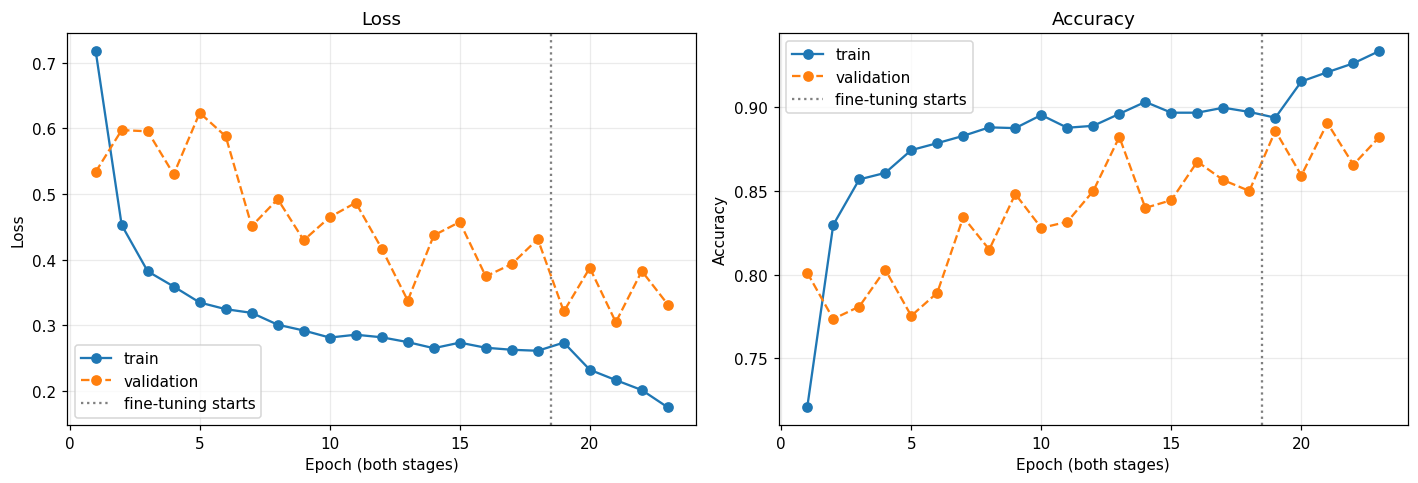

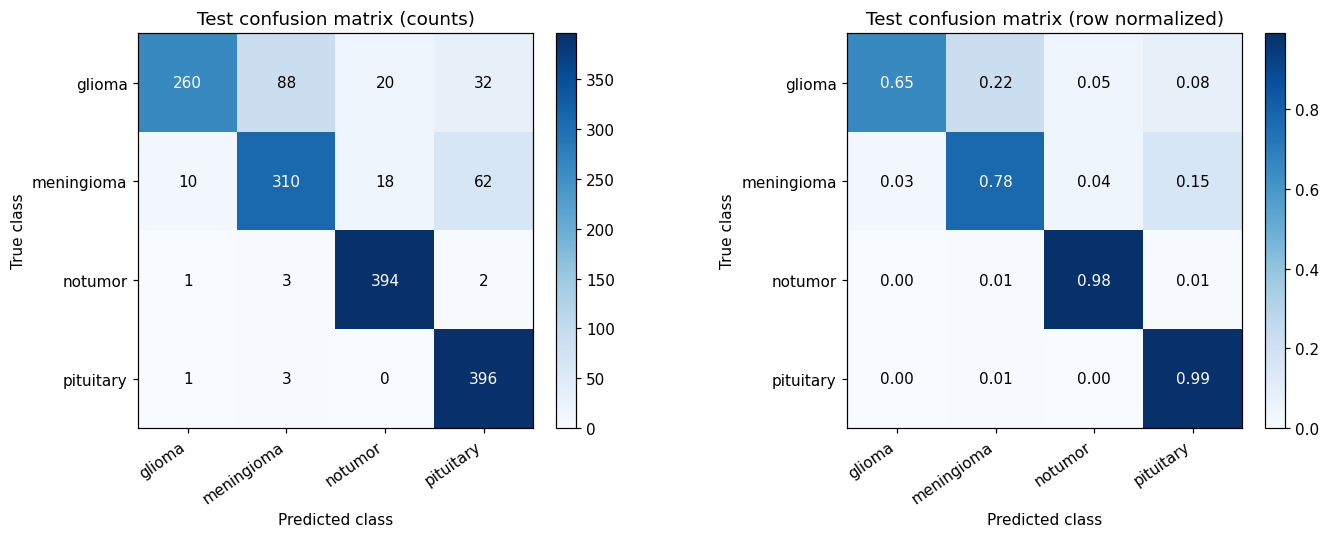

In [15]:
epochs_axis = np.arange(1, len(history_df) + 1)
fine_tune_start = history_df.index[history_df["phase"] == "fine_tuning"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for axis, metric, title in ((axes[0], "loss", "Loss"), (axes[1], "accuracy", "Accuracy")):
    axis.plot(epochs_axis, history_df[metric], marker="o", label="train")
    axis.plot(epochs_axis, history_df[f"val_{metric}"], marker="o", linestyle="--", label="validation")
    if len(fine_tune_start):
        axis.axvline(fine_tune_start[0] + 0.5, color="gray", linestyle=":", label="fine-tuning starts")
    axis.set(title=title, xlabel="Epoch (both stages)", ylabel=title)
    axis.grid(alpha=0.25)
    axis.legend()
plt.tight_layout()
save_figure(fig, "training_curves.png")
plt.show()

matrix = np.asarray(test_metrics["confusion_matrix"])
row_totals = matrix.sum(axis=1, keepdims=True)
normalized = np.divide(matrix, row_totals, out=np.zeros(matrix.shape, dtype=float), where=row_totals != 0)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for axis, values, title, fmt in (
    (axes[0], matrix, "Test confusion matrix (counts)", "d"),
    (axes[1], normalized, "Test confusion matrix (row normalized)", ".2f"),
):
    image = axis.imshow(values, cmap="Blues", vmin=0)
    axis.set(
        title=title, xlabel="Predicted class", ylabel="True class",
        xticks=np.arange(N_CLASSES), yticks=np.arange(N_CLASSES),
        xticklabels=class_names, yticklabels=class_names,
    )
    plt.setp(axis.get_xticklabels(), rotation=35, ha="right")
    threshold = values.max() / 2 if values.max() > 0 else 1
    for row in range(N_CLASSES):
        for col in range(N_CLASSES):
            axis.text(
                col, row, format(values[row, col], fmt), ha="center", va="center",
                color="white" if values[row, col] > threshold else "black",
            )
    fig.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
plt.tight_layout()
save_figure(fig, "confusion_matrix.png")
plt.show()

---
## 10. ROC and precision-recall curves

One-vs-rest curves for each class on the test split. AUC and average precision are undefined when a class has no positive or no negative examples, so such classes are skipped.

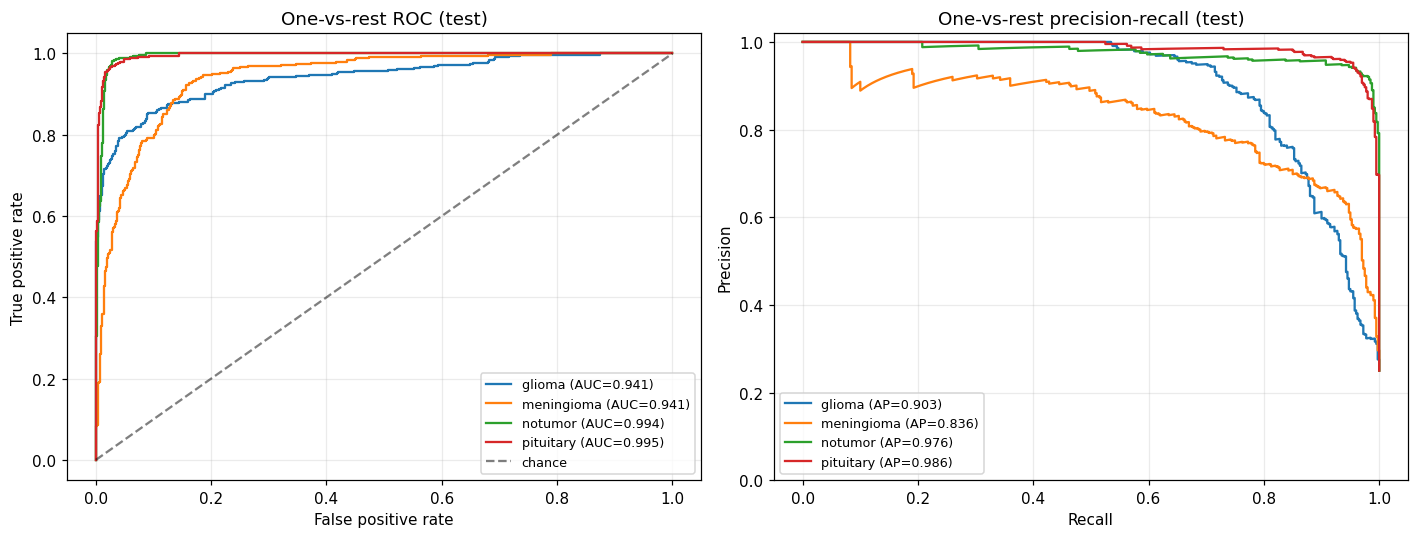

In [16]:
y_true = eval_cache["test"]["y_true"]
probabilities = eval_cache["test"]["probabilities"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for class_id, class_name in enumerate(class_names):
    positive = y_true == class_id
    if not positive.any() or positive.all():
        continue
    fpr, tpr, _ = roc_curve(positive, probabilities[:, class_id])
    precision, recall, _ = precision_recall_curve(positive, probabilities[:, class_id])
    axes[0].plot(fpr, tpr, label=f"{class_name} (AUC={test_metrics['per_class_roc_auc_ovr'][class_name]:.3f})")
    axes[1].plot(recall, precision, label=f"{class_name} (AP={test_metrics['per_class_average_precision_ovr'][class_name]:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="chance")
axes[0].set(title="One-vs-rest ROC (test)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="One-vs-rest precision-recall (test)", xlabel="Recall", ylabel="Precision", ylim=(0, 1.02))
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(fontsize="small")
plt.tight_layout()
save_figure(fig, "roc_pr_curves.png")
plt.show()

---
## 11. Calibration and error review

The reliability diagram compares top-class confidence with empirical accuracy [4]; points below the diagonal indicate over-confidence. ECE depends on the binning and does not guarantee calibrated probabilities. Then inspect the highest-confidence mistakes: check for label noise, duplicate or near-duplicate images, and systematic confusions between specific classes.

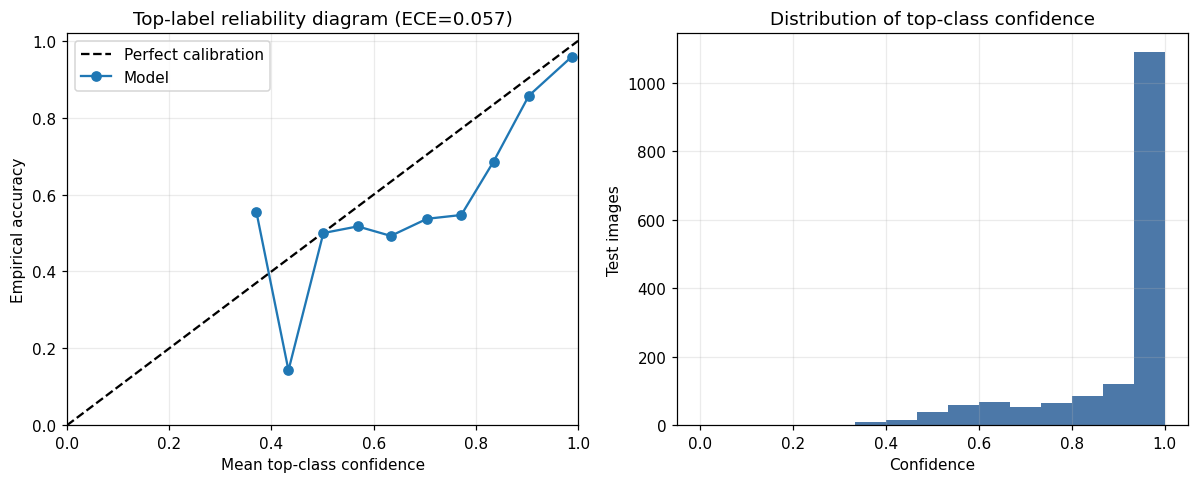

Misclassified test images: 240 / 1600
Highest-confidence errors:


,image_path,true_class,predicted_class,confidence
397,/content/drive/MyDrive/brain_mri_project/Testi...,glioma,notumor,0.999442
702,/content/drive/MyDrive/brain_mri_project/Testi...,meningioma,notumor,0.998918
778,/content/drive/MyDrive/brain_mri_project/Testi...,meningioma,notumor,0.996180
132,/content/drive/MyDrive/brain_mri_project/Testi...,glioma,notumor,0.995732
143,/content/drive/MyDrive/brain_mri_project/Testi...,glioma,meningioma,0.993749
80,/content/drive/MyDrive/brain_mri_project/Testi...,glioma,meningioma,0.993749
505,/content/drive/MyDrive/brain_mri_project/Testi...,meningioma,pituitary,0.993676
239,/content/drive/MyDrive/brain_mri_project/Testi...,glioma,meningioma,0.993597
386,/content/drive/MyDrive/brain_mri_project/Testi...,glioma,meningioma,0.993396
701,/content/drive/MyDrive/brain_mri_project/Testi...,meningioma,notumor,0.992824


Error counts (rows = true class, columns = predicted class):


predicted_class,glioma,meningioma,notumor,pituitary
true_class,,,,
glioma,0,88,20,32
meningioma,10,0,18,62
notumor,1,3,0,2
pituitary,1,3,0,0


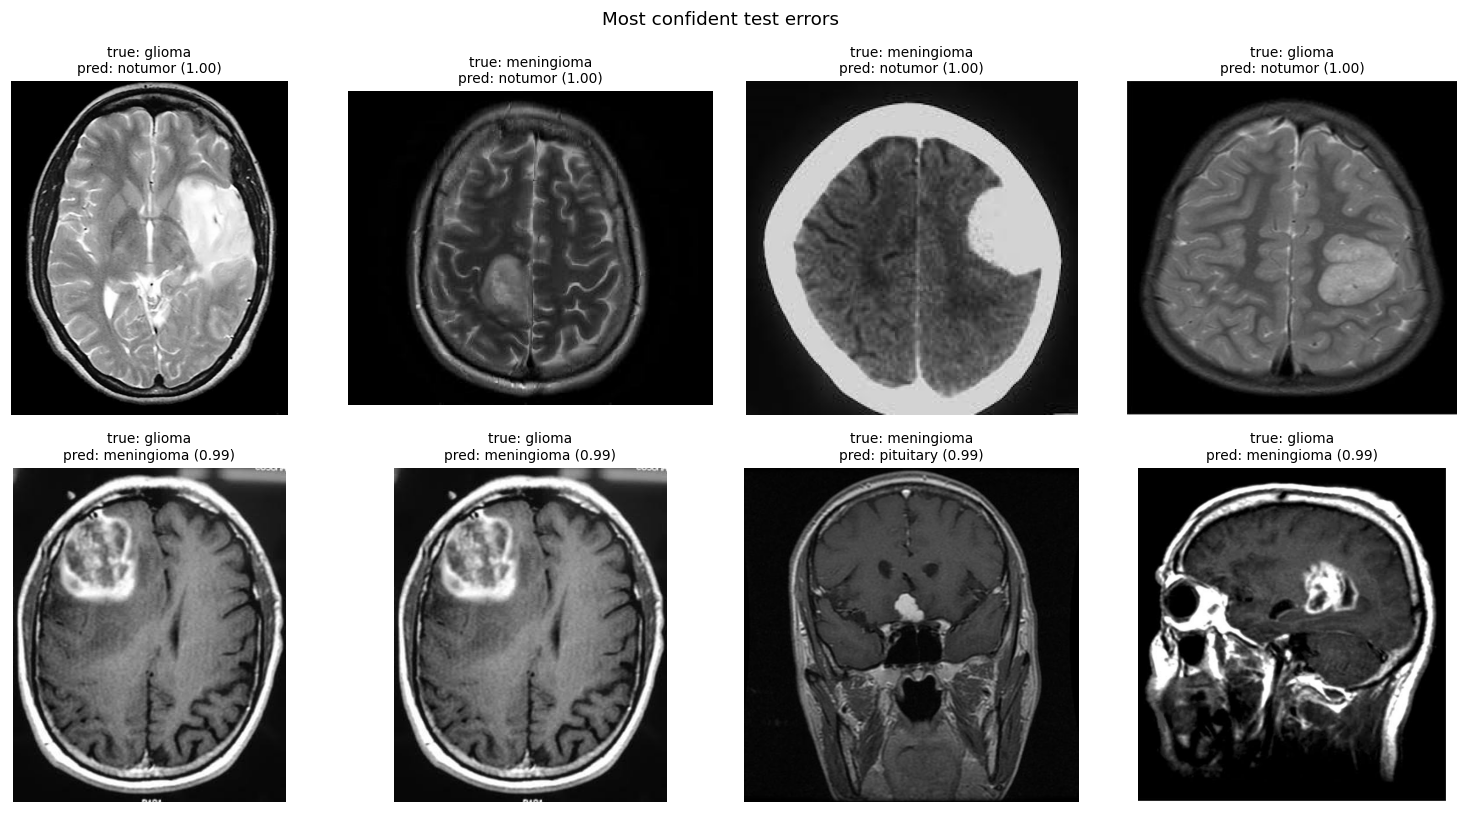

In [17]:
ece, mean_confidence, bin_accuracy, bin_sizes = calibration_summary(y_true, probabilities)
confidence = probabilities.max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot([0, 1], [0, 1], "k--", label="Perfect calibration")
axes[0].plot(mean_confidence, bin_accuracy, "o-", label="Model")
axes[0].set(
    title=f"Top-label reliability diagram (ECE={ece:.3f})",
    xlabel="Mean top-class confidence", ylabel="Empirical accuracy",
    xlim=(0, 1), ylim=(0, 1.02),
)
axes[0].legend()
axes[1].hist(confidence, bins=CALIBRATION_BINS, range=(0, 1), color="#4c78a8")
axes[1].set(title="Distribution of top-class confidence", xlabel="Confidence", ylabel="Test images")
for axis in axes:
    axis.grid(alpha=0.25)
plt.tight_layout()
save_figure(fig, "calibration.png")
plt.show()

predictions_df = eval_cache["test"]["predictions"]
errors_df = predictions_df[~predictions_df["correct"]].sort_values("confidence", ascending=False)
print(f"Misclassified test images: {len(errors_df)} / {len(predictions_df)}")
if len(errors_df):
    print("Highest-confidence errors:")
    display(errors_df.head(20)[["image_path", "true_class", "predicted_class", "confidence"]])
    print("Error counts (rows = true class, columns = predicted class):")
    display(pd.crosstab(errors_df["true_class"], errors_df["predicted_class"]))

    shown = errors_df.head(8)
    fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
    for axis in axes.ravel():
        axis.axis("off")
    for axis, (_, row) in zip(axes.ravel(), shown.iterrows()):
        axis.imshow(Image.open(row["image_path"]).convert("RGB"))
        axis.set_title(f"true: {row['true_class']}\npred: {row['predicted_class']} ({row['confidence']:.2f})", fontsize=9)
    plt.suptitle("Most confident test errors")
    plt.tight_layout()
    save_figure(fig, "top_errors.png")
    plt.show()

---
## 12. Grad-CAM

Grad-CAM [3] weights the last convolutional feature maps by the gradient of the predicted class score, giving a coarse heat map of regions that influenced the model.

* Leave `IMAGE_PATH = None` to explain `GRADCAM_SAMPLES_PER_CLASS` random test images per class, or set it to one authorized image (absolute path, or relative to `PROJECT_DIR`).
* The map is low-resolution (the backbone's final feature grid) and is **not** a tumor segmentation, a causal explanation, or clinical evidence. Highlights on borders, skull, or image artifacts are a warning sign of shortcut learning.

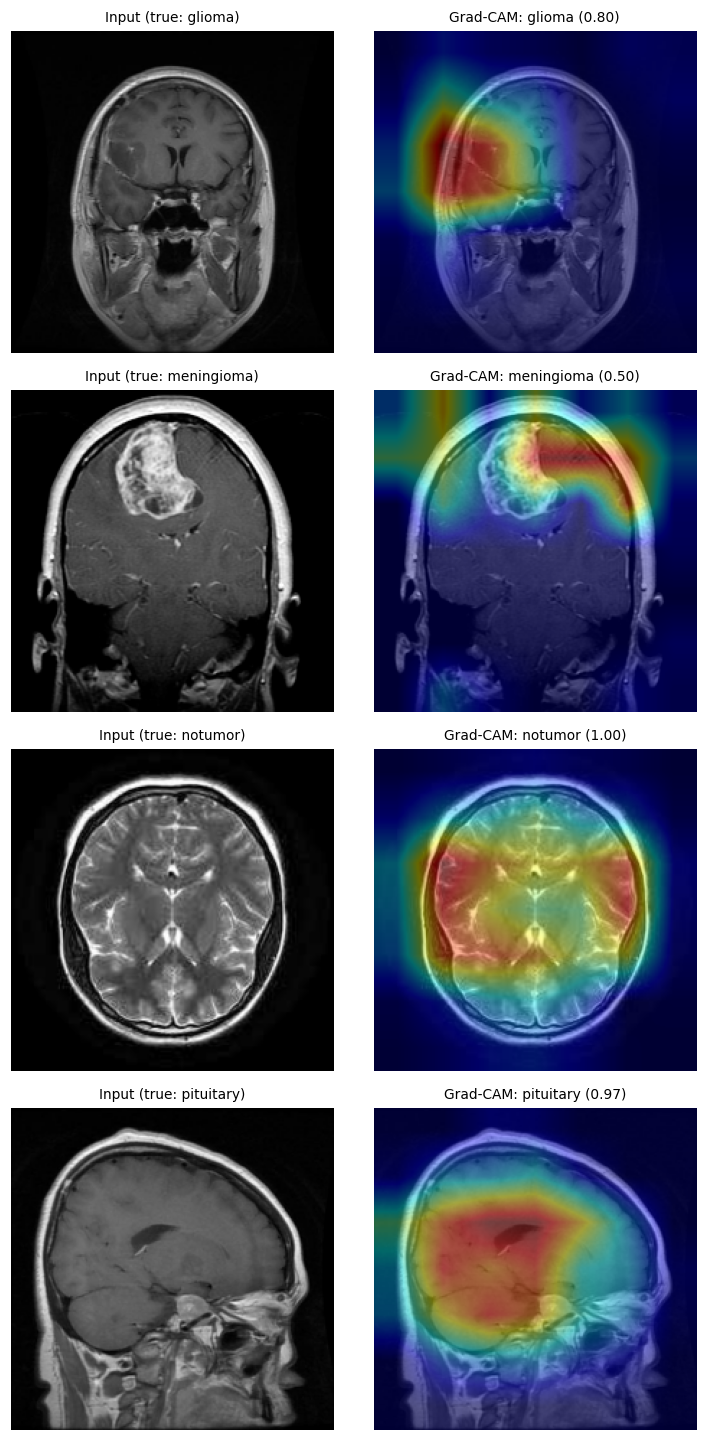

In [18]:
IMAGE_PATH = None                # e.g. DATA_DIR / "Testing" / class_names[0] / "image.jpg"
GRADCAM_SAMPLES_PER_CLASS = 1    # used only when IMAGE_PATH is None


def load_rgb(path):
    """Load an image exactly as the training pipeline does (uint8, IMAGE_SIZE x IMAGE_SIZE x 3)."""
    image, _ = load_image(tf.constant(str(path)), tf.constant(0))
    return image.numpy()


def make_gradcam(trained_model, rgb_image, class_index=None):
    if rgb_image.ndim != 3 or rgb_image.shape[-1] != 3:
        raise ValueError("Expected one RGB image with shape (height, width, 3).")
    backbone_layer = trained_model.get_layer("feature_extractor")
    conv_model = tf.keras.Model(backbone_layer.input, backbone_layer.get_layer("out_relu").output)

    image_batch = tf.convert_to_tensor(rgb_image[np.newaxis, ...], dtype=tf.float32)
    augmented = trained_model.get_layer("data_augmentation")(image_batch, training=False)
    normalized = trained_model.get_layer("mobilenet_preprocess")(augmented)
    conv_output = conv_model(normalized, training=False)

    with tf.GradientTape() as tape:
        tape.watch(conv_output)   # needed even when the backbone is frozen
        pooled = trained_model.get_layer("global_pool")(conv_output)
        dropped = trained_model.get_layer("dropout")(pooled, training=False)
        logits = trained_model.get_layer("class_logits")(dropped)
        predictions = trained_model.get_layer("predictions")(logits)
        selected = int(tf.argmax(predictions[0]).numpy()) if class_index is None else int(class_index)
        if not 0 <= selected < N_CLASSES:
            raise ValueError(f"class_index must be in [0, {N_CLASSES - 1}].")
        class_score = logits[:, selected]

    gradients = tape.gradient(class_score, conv_output)
    if gradients is None:
        raise RuntimeError("Grad-CAM gradients could not be computed.")
    weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    heatmap = tf.maximum(tf.reduce_sum(weights * conv_output, axis=-1)[0], 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + tf.keras.backend.epsilon())
    return heatmap.numpy(), selected, predictions[0].numpy()


def overlay_heatmap(rgb_image, heatmap):
    heatmap = cv2.resize(heatmap, (rgb_image.shape[1], rgb_image.shape[0]))
    colored = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
    colored = cv2.cvtColor(colored, cv2.COLOR_BGR2RGB)
    return cv2.addWeighted(rgb_image, 0.6, colored, 0.4, 0)


if IMAGE_PATH is None:
    rng = np.random.default_rng(SEED)
    targets = []
    for class_id, class_name in enumerate(class_names):
        candidates = [p for p, l in zip(test_paths, test_labels) if l == class_id]
        count = min(GRADCAM_SAMPLES_PER_CLASS, len(candidates))
        targets += [(str(p), class_name) for p in rng.choice(candidates, size=count, replace=False)]
else:
    path = Path(IMAGE_PATH)
    targets = [(str(path if path.is_absolute() else DATA_DIR / path), None)]

fig, axes = plt.subplots(len(targets), 2, figsize=(7, 3.3 * len(targets)), squeeze=False)
for row, (image_path, true_name) in enumerate(targets):
    rgb = load_rgb(image_path)
    heatmap, class_id, scores = make_gradcam(model, rgb)
    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title("Input" + (f" (true: {true_name})" if true_name else ""), fontsize=9)
    axes[row, 1].imshow(overlay_heatmap(rgb, heatmap))
    axes[row, 1].set_title(f"Grad-CAM: {class_names[class_id]} ({scores[class_id]:.2f})", fontsize=9)
    for axis in axes[row]:
        axis.axis("off")
plt.tight_layout()
save_figure(fig, "gradcam.png")
plt.show()

---
## 13. Predict a single image

`predict_image()` returns the class probabilities for one image. To reuse the saved model in a **new session**, run the setup cells, then load it with `tf.keras.models.load_model(".../brain_mri_classifier.keras")` and read the class order from `class_names.json`; never assume alphabetical order.

In [19]:
def predict_image(image_path):
    """Return class probabilities (sorted) for one image file."""
    rgb = load_rgb(image_path).astype("float32")
    probabilities = model.predict(rgb[np.newaxis, ...], verbose=0)[0]
    return pd.Series(probabilities, index=class_names, name="probability").sort_values(ascending=False)


example_path = test_paths[0]
print(f"Example: {example_path} (true class: {class_names[int(test_labels[0])]})")
display(predict_image(example_path).to_frame())
print("Educational demo only: not a diagnosis.")

Example: /content/drive/MyDrive/brain_mri_project/Testing/glioma/Te-gl_1.jpg (true class: glioma)


,probability
notumor,0.621330
pituitary,0.189202
meningioma,0.175751
glioma,0.013718


Educational demo only: not a diagnosis.


---
## 14. Save and download results

Final synchronization: all figures and files from this run are copied to `artifacts/<run id>/` in your Drive project folder and zipped. Drive keeps the files even if the Colab runtime is recycled.

In [20]:
files = sorted(OUTPUT_DIR.iterdir())
display(
    pd.DataFrame(
        {"file": [f.name for f in files], "size (KB)": [round(f.stat().st_size / 1024, 1) for f in files]}
    ).set_index("file")
)
archive_path = sync_results()

# Optional: download the archive straight to your computer from Colab.
# if IN_COLAB:
#     from google.colab import files as colab_files
#     colab_files.download(archive_path)

,size (KB)
file,
brain_mri_classifier.keras,21279.9
calibration.png,80.8
class_distribution.png,39.4
class_names.json,0.1
confusion_matrix.png,89.0
gradcam.png,1140.3
metrics.json,3.3
roc_pr_curves.png,121.1
run_config.json,1.0


Results saved to: /content/drive/MyDrive/brain_mri_project/artifacts/run_20261117_152417
Downloadable archive: /content/drive/MyDrive/brain_mri_project/artifacts/run_20261117_152417.zip


---
## 15. Limitations and responsible use

* **Not a clinical tool.** The model is trained on a small public dataset of 2-D slices. It has no regulatory clearance, and any high test score applies to *this* dataset only.
* **Patient-level leakage is possible.** Public datasets rarely include patient IDs. Several slices from one patient may fall into different splits, which inflates scores [18]. Exact-duplicate checks do not remove this risk.
* **No external validation.** Different scanners, protocols, sequences, planes, and populations can change performance drastically. Evaluate on independent data from a different source before drawing any conclusion.
* **Label quality.** Labels were not re-verified here. Review the highest-confidence errors in Section 11.
* **Class imbalance and subgroups.** Aggregate metrics can hide poor performance for a class or subgroup; read the per-class tables and confidence intervals, not only accuracy.
* **Calibration.** Softmax confidence is often over-confident [4]; do not treat it as a probability of being correct without checking calibration.
* **Interpretability.** Grad-CAM maps are coarse and can look plausible for wrong reasons [3].
* **Reproducibility.** Seeds are fixed, but GPU operations are not bit-for-bit deterministic, so small run-to-run differences are normal. Library versions are stored in `run_config.json`.
* **Data protection.** Respect licences, consent, and local regulations (for example HIPAA or GDPR) before using real patient data.

---
## 16. References

1. Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018). MobileNetV2: Inverted residuals and linear bottlenecks. *IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)*. arXiv:1801.04381.
2. Deng, J., Dong, W., Socher, R., Li, L.-J., Li, K., & Fei-Fei, L. (2009). ImageNet: A large-scale hierarchical image database. *IEEE CVPR*.
3. Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D., & Batra, D. (2017). Grad-CAM: Visual explanations from deep networks via gradient-based localization. *IEEE International Conference on Computer Vision (ICCV)*. arXiv:1610.02391.
4. Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. *Proceedings of the 34th International Conference on Machine Learning (ICML)*, PMLR 70. arXiv:1706.04599.
5. Nickparvar, M. (2021). *Brain Tumor MRI Dataset* [Data set]. Kaggle. https://doi.org/10.34740/KAGGLE/DSV/2645886
6. Cheng, J. (2017). *brain tumor dataset*. figshare. https://doi.org/10.6084/m9.figshare.1512427.v8
7. Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *International Conference on Learning Representations (ICLR)*. arXiv:1412.6980.
8. Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research, 15*, 1929-1958.
9. Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
10. Abadi, M., et al. (2016). TensorFlow: Large-scale machine learning on heterogeneous distributed systems. arXiv:1603.04467.
11. Chollet, F., et al. (2015). *Keras*. https://keras.io
12. Brier, G. W. (1950). Verification of forecasts expressed in terms of probability. *Monthly Weather Review, 78*(1), 1-3.
13. Matthews, B. W. (1975). Comparison of the predicted and observed secondary structure of T4 phage lysozyme. *Biochimica et Biophysica Acta, 405*(2), 442-451.
14. Cohen, J. (1960). A coefficient of agreement for nominal scales. *Educational and Psychological Measurement, 20*(1), 37-46.
15. Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.
16. Yosinski, J., Clune, J., Bengio, Y., & Lipson, H. (2014). How transferable are features in deep neural networks? *Advances in Neural Information Processing Systems 27 (NeurIPS)*.
17. Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90-95.
18. Kapoor, S., & Narayanan, A. (2023). Leakage and the reproducibility crisis in machine-learning-based science. *Patterns, 4*(9), 100804.

*Software used:* TensorFlow / Keras [10, 11], scikit-learn [9], Matplotlib [17], pandas, NumPy, OpenCV, and Pillow.